In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)

cols = ["id", "diagnosis"]
base = ["radius","texture","perimeter","area","smoothness",
        "compactness","concavity","concave_points","symmetry","fractal_dim"]
for s in ["mean","se","worst"]:
    cols += [f"{b}_{s}" for b in base]

df = pd.read_csv("../data/wdbc.data", header=None, names=cols).drop(columns="id")
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})
print(df.shape)
df.head()

(569, 31)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dim_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [2]:
print(df.isna().sum().sum(), "valores faltantes")
print(df.duplicated().sum(), "filas duplicadas")
print(df["diagnosis"].value_counts())
print(df["diagnosis"].value_counts(normalize=True).round(3))
df.describe().T.head(10)

0 valores faltantes
0 filas duplicadas
diagnosis
0    357
1    212
Name: count, dtype: int64
diagnosis
0    0.627
1    0.373
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
diagnosis,569.0,0.372583,0.483918,0.00000,0.00000,0.00000,1.0000,1.0000
radius_mean,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.7800,28.1100
texture_mean,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.8000,39.2800
perimeter_mean,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.1000,188.5000
area_mean,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.7000,2501.0000
smoothness_mean,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.1053,0.1634
compactness_mean,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.1304,0.3454
concavity_mean,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.1307,0.4268
concave_points_mean,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.0740,0.2012
symmetry_mean,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.1957,0.3040


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_10860\3868254891.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax[0].set_xticklabels(["Benigno (0)", "Maligno (1)"])


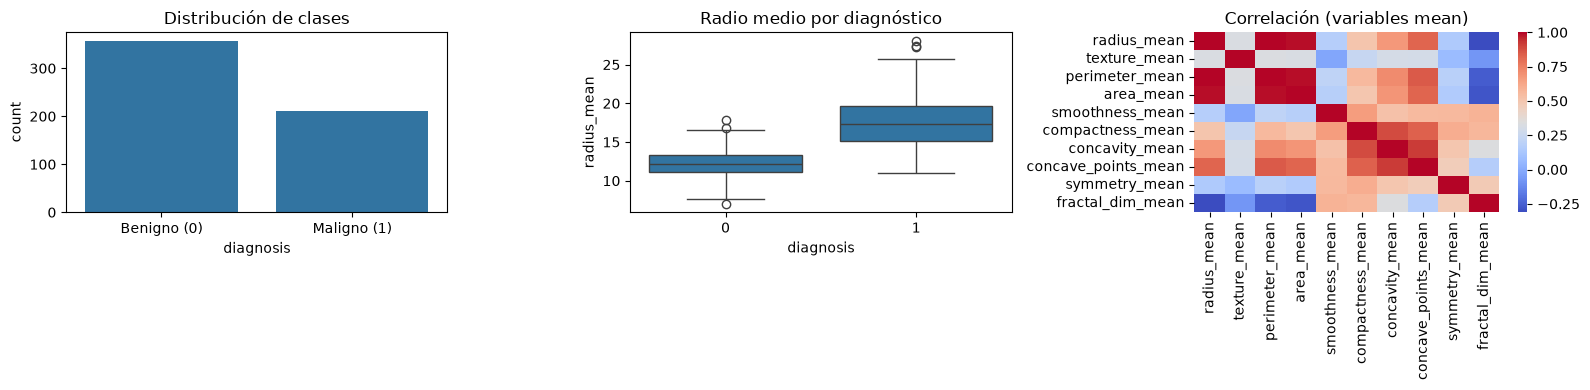

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# 1. Proporción de clases
sns.countplot(x="diagnosis", data=df, ax=ax[0])
ax[0].set_xticklabels(["Benigno (0)", "Maligno (1)"])
ax[0].set_title("Distribución de clases")

# 2. Distribución de una variable por clase
sns.boxplot(x="diagnosis", y="radius_mean", data=df, ax=ax[1])
ax[1].set_title("Radio medio por diagnóstico")

# 3. Correlación entre las variables "mean"
mean_cols = [c for c in df.columns if c.endswith("_mean")]
sns.heatmap(df[mean_cols].corr(), cmap="coolwarm", ax=ax[2])
ax[2].set_title("Correlación (variables mean)")

plt.tight_layout()
plt.savefig("../reports/figures/eda_basico.png", dpi=150)
plt.show()

1.Distribución de clases: hay unos 357 benignos y 212 malignos (62.7% / 37.3%). El desbalance es moderado, así que la exactitud sirve, pero conviene reportar también recall y F1 y usar partición estratificada.
2.Radio medio por diagnóstico: los tumores malignos tienen radios claramente mayores (mediana cercana a 17-18 frente a ~12 en benignos), con poco traslape entre las cajas. Esta variable por sí sola ya separa bastante bien las clases. Se ven algunos valores atípicos en ambos grupos.
3.Correlación (variables mean): radio, perímetro y área son casi perfectamente correlacionados (zona roja intensa, ~0.99). También hay correlación alta entre compacidad, concavidad y puntos cóncavos. Esto viola el supuesto de independencia condicional de Naive Bayes y puede causar multicolinealidad en la regresión logística.